In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar `proyecto` sin instalarlo: el código vive en src/
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

# 07 · Validación e interpretación: abrir la prueba, una sola vez

Hasta aquí todo se decidió con **validación**. La **prueba** (el 20 % de los prestatarios, que nadie ha mirado) se abre
hoy, **una sola vez**, para medir cómo se comportará el modelo con prestatarios nuevos. Por eso el orden importa:

1. Con datos **reservados** (no con la prueba) se confirma el modelo y se decide si se calibra y qué umbral se usa.
2. Esas decisiones se **escriben y se guardan con fecha y hora** antes de abrir nada.
3. Recién entonces se abre la prueba, y su resultado **no se usa para volver a decidir**.

Los datos son `train_sin_memberkey.parquet` y `test_sin_memberkey.parquet`. `borrower_id` es un número anónimo: mantiene
juntos los préstamos de cada prestatario, pero **no entra al modelo**.

## 0. Cargar el entrenamiento y reconstruir la reserva

Se usa la **misma reserva de la etapa 6**: el 25 % de los prestatarios del entrenamiento (semilla 7), que la búsqueda
de hiperparámetros no vio. La prueba **no se carga todavía**.

> **Comprobación de la reserva.** Los ensayos de `optuna_06.db` se hicieron con una reserva de 9.910 préstamos. Si sale
> otro número (por ejemplo, con otra versión de scikit-learn), parte de los prestatarios ya se usó para elegir los
> parámetros, y la reserva deja de ser limpia. En ese caso el notebook se detiene.

In [2]:
import json
from datetime import datetime

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import average_precision_score, confusion_matrix

from proyecto.config import (
    ANONYMOUS_GROUP_COL, CLASSES, COST_MATRIX, MODELS_DIR, PROCESSED_DIR, PROSPER_RATING_START, RANDOM_STATE, REPORTS_DIR,
    TARGET,
)
from proyecto.data.split import assert_disjoint_members, group_cv, split_by_member
from proyecto.features.engineering import FINAL_FEATURES
from proyecto.models.train import (
    build_pipeline, candidates, decide_min_cost, encode_target, expected_cost, feature_frame, metrics_from_proba,
)
from proyecto.models.tuning import MODELS, bootstrap_cost_difference, bootstrap_metric_ci, bootstrap_metric_difference, pr_auc

EXPECTED_RESERVED_ROWS = 9_910   # préstamos reservados con los que se hizo la búsqueda de la etapa 6
USD_PER_COST_UNIT = 1_154.30     # 1 unidad de costo = rechazar a un buen cliente (reports/05_torneo.md)


def split_xy(df):
    """Separa variables y objetivo; `borrower_id` queda fuera de las variables del modelo."""
    return feature_frame(df).drop(columns=[ANONYMOUS_GROUP_COL]), encode_target(df[TARGET])


train = pd.read_parquet(PROCESSED_DIR / "train_sin_memberkey.parquet")
tune_df, val_df = split_by_member(train, test_size=0.25, seed=7, group_col=ANONYMOUS_GROUP_COL)
assert_disjoint_members(tune_df, val_df, group_col=ANONYMOUS_GROUP_COL)
if len(val_df) != EXPECTED_RESERVED_ROWS:
    raise RuntimeError(
        f"La reserva tiene {len(val_df):,} préstamos y debería tener {EXPECTED_RESERVED_ROWS:,}. "
        f"scikit-learn {sklearn.__version__}: usa las versiones de requirements.txt antes de seguir."
    )
X_train, y_train = split_xy(train)
X_tune, y_tune = split_xy(tune_df)
X_val, y_val = split_xy(val_df)
print(f"entrenamiento: {len(train):,} préstamos, {train[ANONYMOUS_GROUP_COL].nunique():,} prestatarios")
print(f"búsqueda: {len(tune_df):,} préstamos · reserva: {len(val_df):,} préstamos · scikit-learn {sklearn.__version__}")

entrenamiento: 39,641 préstamos, 32,341 prestatarios
búsqueda: 29,731 préstamos · reserva: 9,910 préstamos · scikit-learn 1.9.1


## 1. Reglas escritas **antes** de mirar los resultados

| Decisión | Regla | Con qué datos |
|---|---|---|
| **Modelo y parámetros** | Los que dejó la etapa 6: LightGBM optimizado. Aquí no se vuelven a elegir | Reserva de la etapa 6 |
| **Calibración** | Método sigmoide con pliegues por prestatario. Se calibra solo si el log loss baja más de 0,005 **y** el costo no empeora de forma distinguible | Reserva |
| **Regla de decisión** | Menor costo esperado con la matriz 4 a 1: marcar impago si P(impago) > 0,2 | Matriz de costos del caso |
| **Umbral por capacidad** | No se adopta: el proyecto no tiene una cifra de capacidad del analista. Se muestra la tabla de umbrales para que el negocio decida | Reserva |
| **Métrica principal** | AUC-PR de impago. Controles: costo, ROC-AUC, Brier, recall y F1 de impago | Prueba |
| **Superar la línea base** | El intervalo de la diferencia de AUC-PR queda entero sobre 0 **y** el de costo entero bajo 0 | Prueba |
| **Índice climático** | Se mide con y sin él en la prueba, porque es la pregunta del caso. **El resultado no cambia el modelo** | Prueba |
| **Desde julio de 2009** | Se reporta aparte: desde esa fecha Prosper asigna su puntaje actual | Prueba |

In [3]:
best = json.loads((REPORTS_DIR / "06_mejores_parametros.json").read_text(encoding="utf-8"))
final_name, final_params = best["modelo_final"], best["parametros"]
_, make_fn, scale = MODELS[final_name]
if best["parametros_elegidos"] != "optimizado":
    raise RuntimeError("La etapa 6 eligió parámetros de partida: revisa este notebook antes de seguir.")


def new_pipeline(**extra_flags):
    """Pipeline sin ajustar con el modelo y las variables finales; `extra_flags` activa variantes."""
    return build_pipeline(make_fn(final_params), scale=scale, **{**FINAL_FEATURES, **extra_flags})


uncalibrated = new_pipeline().fit(X_tune, y_tune)
tune_folds = list(group_cv(n_splits=3, seed=RANDOM_STATE).split(X_tune, y_tune, groups=tune_df[ANONYMOUS_GROUP_COL]))
calibrated = CalibratedClassifierCV(new_pipeline(), method="sigmoid", cv=tune_folds).fit(X_tune, y_tune)

p_uncal, p_cal = uncalibrated.predict_proba(X_val), calibrated.predict_proba(X_val)
m_uncal, m_cal = metrics_from_proba(y_val, p_uncal), metrics_from_proba(y_val, p_cal)
cost_diff, cost_low, cost_high = bootstrap_cost_difference(y_val, p_cal, p_uncal, val_df[ANONYMOUS_GROUP_COL])
calibrate = bool(m_cal["log_loss"] < m_uncal["log_loss"] - 0.005 and cost_low <= 0)

pd.DataFrame({"sin calibrar": m_uncal, "calibrado": m_cal}).loc[["pr_auc", "log_loss", "brier", "cost", "flagged_rate"]].round(4)

,sin calibrar,calibrado
pr_auc,0.6080,0.6086
log_loss,0.5088,0.5087
brier,0.1698,0.1697
cost,0.5073,0.5082
flagged_rate,0.6300,0.6309


costo calibrado − sin calibrar: +0.0009  IC 95 % [-0.0056; +0.0072]
¿calibrar? no


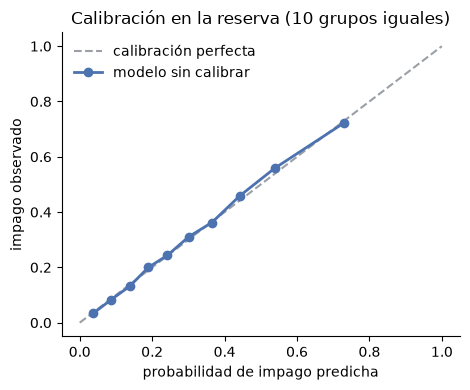

In [4]:
print(f"costo calibrado − sin calibrar: {cost_diff:+.4f}  IC 95 % [{cost_low:+.4f}; {cost_high:+.4f}]")
print("¿calibrar?", "sí" if calibrate else "no")

frequency, predicted = calibration_curve(y_val, p_uncal[:, 1], n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.plot([0, 1], [0, 1], "--", color="#9aa0a6", linewidth=1.5, label="calibración perfecta")
ax.plot(predicted, frequency, "o-", color="#4c72b0", linewidth=2, label="modelo sin calibrar")
ax.set_xlabel("probabilidad de impago predicha"); ax.set_ylabel("impago observado")
ax.set_title("Calibración en la reserva (10 grupos iguales)"); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### Umbrales: lo que cuesta y lo que da cada uno, en la reserva

El umbral de 0,2 sale de la matriz de costos. La tabla muestra qué pasaría si la capacidad del analista obligara a marcar
menos solicitudes. **Es información para el negocio, no una decisión de esta etapa.**

In [5]:
p_selected = (p_cal if calibrate else p_uncal)[:, 1]
rows = []
for threshold in (0.2, 0.3, 0.4, 0.5):
    flagged = (p_selected > threshold).astype(int)
    rows.append({
        "umbral": threshold, "% marcado": flagged.mean(), "recall impago": flagged[y_val == 1].mean(),
        "precisión": y_val[flagged == 1].mean(), "costo": expected_cost(y_val, flagged),
    })
pd.DataFrame(rows).set_index("umbral").round(3)

,% marcado,recall impago,precisión,costo
umbral,,,,
0.2,0.630,0.879,0.433,0.507
0.3,0.453,0.732,0.502,0.558
0.4,0.300,0.561,0.580,0.671
0.5,0.183,0.384,0.652,0.828


### Las decisiones, por escrito

Se guardan en `reports/07_decisiones_congeladas.json` **con fecha y hora**, antes de abrir la prueba. Si la prueba ya se
abrió, el archivo no se reescribe.

In [6]:
decisions = {
    "fecha_y_hora": datetime.now().isoformat(timespec="seconds"),
    "modelo_final": final_name,
    "parametros": final_params,
    "variables": "FINAL_FEATURES (sin índice climático ni borrower_id)",
    "calibrar": calibrate,
    "metrica_principal": "AUC-PR de impago (mayor es mejor)",
    "metricas_de_control": ["costo 4 a 1", "ROC-AUC", "Brier", "recall de impago", "F1 de impago"],
    "regla_de_decision": "menor costo esperado con la matriz 4 a 1: marcar impago si P(impago) > 0,2",
    "linea_base": "proporción de impagos del entrenamiento (la del torneo)",
    "como_se_decidio": "reserva de prestatarios de la etapa 6 (25 % del entrenamiento); la prueba no se miró",
    "reserva": {"prestamos": len(val_df), "pr_auc": m_uncal["pr_auc"], "cost": m_uncal["cost"]},
    "calibracion": {
        "metodo": "sigmoide", "log_loss_sin": m_uncal["log_loss"], "log_loss_con": m_cal["log_loss"],
        "costo_sin": m_uncal["cost"], "costo_con": m_cal["cost"],
        "diferencia_costo": cost_diff, "ic95_costo": [cost_low, cost_high],
    },
}
decisions_path, test_mark = REPORTS_DIR / "07_decisiones_congeladas.json", REPORTS_DIR / "prueba_abierta.txt"
if decisions_path.exists():
    decisions = json.loads(decisions_path.read_text(encoding="utf-8"))
    print("Las decisiones ya estaban congeladas el", decisions["fecha_y_hora"], "(no se modifican).")
else:
    decisions_path.write_text(json.dumps(decisions, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
    print("Decisiones guardadas:", decisions["fecha_y_hora"])
print("modelo final:", decisions["modelo_final"], "· calibrar:", decisions["calibrar"])

Las decisiones ya estaban congeladas el 2026-11-05T20:09:49 (no se modifican).
modelo final: lightgbm · calibrar: False


## 2. Entrenar el modelo final con **todo** el entrenamiento

Con las decisiones tomadas, el modelo se ajusta con los 39.641 préstamos del entrenamiento, reserva incluida. Se guarda
el pipeline completo, y se ajustan la **línea base** del torneo y la variante **con índice climático**.

In [7]:
base_final = new_pipeline().fit(X_train, y_train)   # sin calibrar: también sirve para SHAP
if decisions["calibrar"]:
    train_folds = list(group_cv(n_splits=3, seed=RANDOM_STATE).split(X_train, y_train, groups=train[ANONYMOUS_GROUP_COL]))
    final_model = CalibratedClassifierCV(new_pipeline(), method="sigmoid", cv=train_folds).fit(X_train, y_train)
else:
    final_model = base_final
baseline_model, baseline_scale = candidates()["línea base (proporción de impago)"]
baseline = build_pipeline(baseline_model, scale=baseline_scale, **FINAL_FEATURES).fit(X_train, y_train)
climate_model = new_pipeline(use_climate=True).fit(X_train, y_train)

joblib.dump(final_model, MODELS_DIR / "final_pipeline.joblib")
print("modelo final ajustado y guardado:", type(final_model).__name__)

modelo final ajustado y guardado: Pipeline


## 3. Abrir la prueba: **una sola vez**

Esta celda escribe la marca `reports/prueba_abierta.txt` y guarda las probabilidades. Si el notebook se vuelve a ejecutar,
**no se vuelve a evaluar el modelo con la prueba**: se reutilizan esas probabilidades.

La compuerta `OPEN_TEST` empieza en `False` para que "Ejecutar todo" no abra la prueba por accidente. Solo se cambia a
`True` cuando el grupo revisó las decisiones de la sección 1.

In [8]:
OPEN_TEST = True

test_cache = PROCESSED_DIR / "prueba_probabilidades.joblib"
if test_mark.exists() and not test_cache.exists():
    raise RuntimeError("La prueba ya se abrió y faltan sus probabilidades: decláralo en el reporte antes de reabrirla.")
if not test_mark.exists() and not OPEN_TEST:
    raise RuntimeError("La prueba sigue CERRADA. Revisa la sección 1 y cambia OPEN_TEST a True para abrirla.")

test = pd.read_parquet(PROCESSED_DIR / "test_sin_memberkey.parquet")
X_test, y_test = split_xy(test)
test_groups = test[ANONYMOUS_GROUP_COL]
assert_disjoint_members(train, test, group_col=ANONYMOUS_GROUP_COL)

if test_mark.exists():
    probabilities = joblib.load(test_cache)
    print("La prueba ya se abrió:", test_mark.read_text(encoding="utf-8").strip())
    print("Se reutilizan sus probabilidades; el modelo no se vuelve a evaluar.")
else:
    probabilities = {
        "final": final_model.predict_proba(X_test), "baseline": baseline.predict_proba(X_test),
        "climate": climate_model.predict_proba(X_test),
    }
    joblib.dump(probabilities, test_cache)
    test_mark.write_text(
        f"Prueba abierta el {datetime.now().isoformat(timespec='seconds')} · modelo {final_name} · "
        f"{len(test):,} préstamos, {test_groups.nunique():,} prestatarios. Una sola vez.\n", encoding="utf-8",
    )
    print("Prueba abierta ahora; marca escrita en", test_mark.name)

p_test, p_baseline, p_climate = probabilities["final"], probabilities["baseline"], probabilities["climate"]
m_test, m_baseline = metrics_from_proba(y_test, p_test), metrics_from_proba(y_test, p_baseline)
pd.DataFrame({"modelo final": m_test, "línea base": m_baseline}).round(4)

Prueba abierta ahora; marca escrita en prueba_abierta.txt


,modelo final,línea base
pr_auc,0.6209,0.3104
roc_auc,0.7780,0.5000
log_loss,0.5068,0.6194
brier,0.1686,0.2140
cost,0.5208,0.6896
cost_argmax,0.8180,1.2414
recall_default,0.8752,1.0000
precision_default,0.4261,0.3104
f1_default,0.5731,0.4737
flagged_rate,0.6375,1.0000


## 4. Intervalos y comparación con la línea base

Una cifra sin intervalo no dice cuánto confiar en ella. Los préstamos de un prestatario no son independientes, así que
el intervalo se calcula remuestreando **prestatarios completos**, no filas (1.000 veces).

In [9]:
def cost_metric(y, p):
    return expected_cost(y, decide_min_cost(np.column_stack([1 - p, p])))


def brier_metric(y, p):
    return float(np.mean((p - y) ** 2))


p1, p1_base = p_test[:, 1], p_baseline[:, 1]
pr_value, pr_low, pr_high = bootstrap_metric_ci(y_test, p1, test_groups, pr_auc, n_boot=1000)
cost_value, cost_ci_low, cost_ci_high = bootstrap_metric_ci(y_test, p1, test_groups, cost_metric, n_boot=1000)
brier_value, brier_low, brier_high = bootstrap_metric_ci(y_test, p1, test_groups, brier_metric, n_boot=1000)
pr_diff, pr_diff_low, pr_diff_high = bootstrap_metric_difference(y_test, p1, p1_base, test_groups, pr_auc, n_boot=1000)
cost_base_diff, cost_base_low, cost_base_high = bootstrap_cost_difference(y_test, p_test, p_baseline, test_groups)

intervals = pd.DataFrame(
    [
        ["AUC-PR (mayor es mejor)", pr_value, pr_low, pr_high],
        ["costo por solicitud (menor es mejor)", cost_value, cost_ci_low, cost_ci_high],
        ["Brier (menor es mejor)", brier_value, brier_low, brier_high],
        ["AUC-PR: modelo − línea base", pr_diff, pr_diff_low, pr_diff_high],
        ["costo: modelo − línea base", cost_base_diff, cost_base_low, cost_base_high],
    ],
    columns=["medida", "valor", "IC 95 % inferior", "IC 95 % superior"],
).set_index("medida")
beats_baseline = bool(pr_diff_low > 0 and cost_base_high < 0)
savings = -cost_base_diff * USD_PER_COST_UNIT * 1_000
print("¿Supera a la línea base con confianza?", "SÍ" if beats_baseline else "NO")
print(f"Ahorro frente a la línea base: {savings:,.0f} USD por cada 1.000 solicitudes")
print(f"AUC-PR en la reserva: {decisions['reserva']['pr_auc']:.4f} · en la prueba: {pr_value:.4f}")
intervals.round(4)

¿Supera a la línea base con confianza? SÍ
Ahorro frente a la línea base: 194,849 USD por cada 1.000 solicitudes
AUC-PR en la reserva: 0.6080 · en la prueba: 0.6209


,valor,IC 95 % inferior,IC 95 % superior
medida,,,
AUC-PR (mayor es mejor),0.6209,0.6044,0.6407
costo por solicitud (menor es mejor),0.5208,0.5043,0.5376
Brier (menor es mejor),0.1686,0.1644,0.1725
AUC-PR: modelo − línea base,0.3105,0.2959,0.3270
costo: modelo − línea base,-0.1688,-0.1887,-0.1485


## 5. Las preguntas pendientes del caso

**¿El índice climático agrega información?** Se compara el modelo con y sin el índice en los mismos préstamos.

**¿Cuánto rinde desde julio de 2009?** Desde esa fecha Prosper usa su puntaje actual, que es el que tendría una solicitud
nueva. Esta cifra es la más cercana al uso real.

In [10]:
climate_diff, climate_low, climate_high = bootstrap_metric_difference(
    y_test, p_climate[:, 1], p1, test_groups, pr_auc, n_boot=1000,
)
climate_cost, climate_cost_low, climate_cost_high = bootstrap_cost_difference(y_test, p_climate, p_test, test_groups)
climate_adds = bool(climate_low > 0)
print(f"AUC-PR con índice − sin índice: {climate_diff:+.4f}  IC 95 % [{climate_low:+.4f}; {climate_high:+.4f}]")
print(f"Costo con índice − sin índice:  {climate_cost:+.4f}  IC 95 % [{climate_cost_low:+.4f}; {climate_cost_high:+.4f}]")
print("¿El índice agrega información distinguible del ruido?", "sí" if climate_adds else "no")

recent = pd.to_datetime(test["LoanOriginationDate"]).ge(pd.Timestamp(PROSPER_RATING_START)).to_numpy()
recent_value, recent_low, recent_high = bootstrap_metric_ci(y_test[recent], p1[recent], test_groups[recent], pr_auc, n_boot=1000)
m_recent, m_old = metrics_from_proba(y_test[recent], p_test[recent]), metrics_from_proba(y_test[~recent], p_test[~recent])
print(f"\nDesde julio de 2009: AUC-PR {recent_value:.4f}  IC 95 % [{recent_low:.4f}; {recent_high:.4f}] · {recent.sum():,} préstamos")
print(f"Tasa de impago: {y_test[recent].mean():.1%} desde julio de 2009 · {y_test[~recent].mean():.1%} antes")
pd.DataFrame({"desde jul. 2009": m_recent, "antes": m_old}).loc[["pr_auc", "roc_auc", "cost", "recall_default", "flagged_rate"]].round(4)

AUC-PR con índice − sin índice: +0.0023  IC 95 % [+0.0003; +0.0045]
Costo con índice − sin índice:  -0.0046  IC 95 % [-0.0106; +0.0010]
¿El índice agrega información distinguible del ruido? sí



Desde julio de 2009: AUC-PR 0.4789  IC 95 % [0.4480; 0.5102] · 5,329 préstamos
Tasa de impago: 24.2% desde julio de 2009 · 39.0% antes


,desde jul. 2009,antes
pr_auc,0.4789,0.6963
roc_auc,0.7506,0.7812
cost,0.5356,0.5037
recall_default,0.7890,0.9373
flagged_rate,0.5222,0.7715


## 6. Errores y carga de trabajo: lo que la métrica no ve

El modelo **prioriza revisión humana**, así que importa cuántas solicitudes marca frente a los impagos que hay en
realidad. Un modelo puede tener el mejor costo y aun así generar demasiado trabajo.

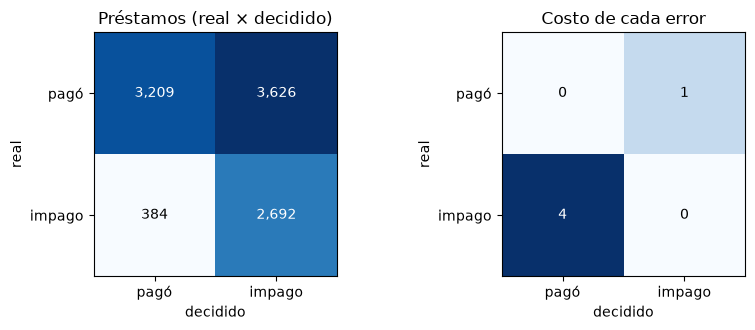

se marcan para revisión: 63.7% de las solicitudes · impagos reales: 31.0%
de cada 100 marcadas, 43 caen en impago
impagos que pasan sin revisión (el error más caro): 384 de 3,076


In [11]:
decision = decide_min_cost(np.column_stack([1 - p1, p1]))
matrix = confusion_matrix(y_test, decision, labels=[0, 1])
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.4))
for ax, data, title, fmt in (
    (axes[0], matrix, "Préstamos (real × decidido)", ",d"),
    (axes[1], COST_MATRIX, "Costo de cada error", ".0f"),
):
    ax.imshow(data, cmap="Blues")
    ax.set_xticks(range(2), CLASSES); ax.set_yticks(range(2), CLASSES)
    ax.set_xlabel("decidido"); ax.set_ylabel("real"); ax.set_title(title)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, format(int(data[i, j]), fmt), ha="center", va="center",
                    color="white" if data[i, j] > data.max() * 0.6 else "black")
plt.tight_layout(); plt.show()

missed = int(((decision == 0) & (y_test == 1)).sum())
print(f"se marcan para revisión: {decision.mean():.1%} de las solicitudes · impagos reales: {y_test.mean():.1%}")
print(f"de cada 100 marcadas, {100 * y_test[decision == 1].mean():.0f} caen en impago")
print(f"impagos que pasan sin revisión (el error más caro): {missed:,} de {int(y_test.sum()):,}")

In [12]:
# Errores por segmento: ¿el modelo funciona igual para todos?
top_states = test["BorrowerState"].value_counts().head(8).index
segments_df = pd.DataFrame({
    "real": y_test, "decidido": decision, "proba": p1, "costo": COST_MATRIX[y_test, decision],
    "época": np.where(recent, "desde jul. 2009", "antes de jul. 2009"),
    "plazo": test["Term"].astype(str).to_numpy(),
    "ingreso": test["IncomeRange"].astype(str).to_numpy(),
    "vivienda propia": test["IsBorrowerHomeowner"].astype(str).to_numpy(),
    "estado": test["BorrowerState"].where(test["BorrowerState"].isin(top_states), "otros").to_numpy(),
})


def summarize(column):
    rows = []
    for value, group in segments_df.groupby(column, observed=True):
        rows.append({
            "segmento": column, "valor": value, "préstamos": len(group), "% impago real": group["real"].mean(),
            "% marcado": group["decidido"].mean(), "recall impago": group.loc[group["real"] == 1, "decidido"].mean(),
            "AUC-PR": average_precision_score(group["real"], group["proba"]) if group["real"].nunique() == 2 else np.nan,
            "costo medio": group["costo"].mean(),
        })
    return pd.DataFrame(rows).set_index(["segmento", "valor"])


segments = pd.concat(summarize(c) for c in ["época", "plazo", "ingreso", "vivienda propia", "estado"])
segments.round(3)

préstamos  % impago real  % marcado  \
segmento        valor                                                     
época           antes de jul. 2009       4582          0.390      0.771   
                desde jul. 2009          5329          0.242      0.522   
plazo           12                        325          0.062      0.031   
                36                       8840          0.317      0.650   
                60                        746          0.335      0.757   
ingreso         $0                        122          0.418      0.779   
                $1-24,999                 882          0.354      0.772   
                $100,000+                1130          0.217      0.420   
                $25,000-49,999           3133          0.327      0.718   
                $50,000-74,999           2470          0.286      0.577   
                $75,000-99,999           1307          0.207      0.500   
                Not displayed             773          0.551      0.865   
                Not employed               94          0.415      0.755   
vivienda propia FALSO                    5108          0.324      0.666   
                VERDADERO                4803          0.296      0.607   
estado          CA                       1460          0.329      0.671   
                FL                        575          0.303      0.612   
                GA                        545          0.332      0.673   
                IL                        579          0.314      0.646   
                MI                        363          0.311      0.647   
                NY                        536          0.220      0.528   
                OH                        348          0.356      0.678   
                TX                        546          0.357      0.672   
                otros                    4959          0.304      0.630   

                                    recall impago  AUC-PR  costo medio  
segmento        valor                                                   
época           antes de jul. 2009          0.937   0.696        0.504  
                desde jul. 2009             0.789   0.479        0.536  
plazo           12                          0.200   0.347        0.215  
                36                          0.876   0.626        0.529  
                60                          0.920   0.584        0.556  
ingreso         $0                          0.941   0.615        0.484  
                $1-24,999                   0.926   0.616        0.549  
                $100,000+                   0.747   0.542        0.478  
                $25,000-49,999              0.886   0.560        0.577  
                $50,000-74,999              0.836   0.551        0.526  
                $75,000-99,999              0.815   0.491        0.484  
                Not displayed               0.977   0.855        0.379  
                Not employed                0.923   0.739        0.500  
vivienda propia FALSO                       0.884   0.638        0.531  
                VERDADERO                   0.865   0.599        0.511  
estado          CA                          0.902   0.653        0.503  
                FL                          0.833   0.523        0.562  
                GA                          0.906   0.659        0.497  
                IL                          0.918   0.631        0.461  
                MI                          0.850   0.675        0.570  
                NY                          0.839   0.583        0.485  
                OH                          0.847   0.527        0.595  
                TX                          0.897   0.764        0.498  
                otros                       0.867   0.599        0.529

## 7. ¿Por qué decide así el modelo? SHAP, con sus límites

SHAP reparte la predicción entre las variables: cuánto empuja cada una hacia el impago. Se calcula sobre una **muestra del
entrenamiento** (1.000 préstamos; la prueba no interviene) y sobre el modelo **sin calibrar**.

> **Tres límites.** SHAP explica **al modelo, no al mundo**: no dice si el modelo acertó. Una importancia alta **no es
> causa**. Y las variables correlacionadas se reparten el crédito, así que quitar una puede subir el aporte de otra.

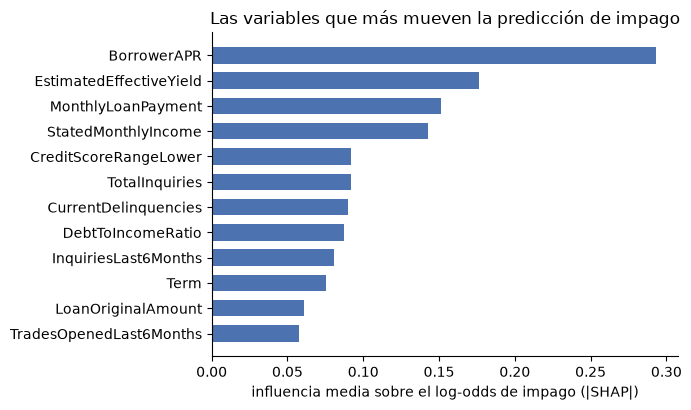

,|SHAP| medio
BorrowerAPR,0.2931
EstimatedEffectiveYield,0.1765
MonthlyLoanPayment,0.1513
StatedMonthlyIncome,0.1428
CreditScoreRangeLower,0.0918
TotalInquiries,0.0917
CurrentDelinquencies,0.0898
DebtToIncomeRatio,0.0874
InquiriesLast6Months,0.0809
Term,0.0757


In [13]:
import shap

sample = train.sample(1_000, random_state=0)
X_sample = sample.drop(columns=[TARGET, ANONYMOUS_GROUP_COL])
preprocessor, tree = base_final.named_steps["prep"], base_final.named_steps["model"]
transformed = preprocessor.transform(base_final.named_steps["features"].transform(X_sample))
names = [name.split("__", 1)[-1] for name in preprocessor.get_feature_names_out()]
values = shap.TreeExplainer(tree).shap_values(transformed, check_additivity=False)
values = values[1] if isinstance(values, list) else values

importance = pd.Series(np.abs(values).mean(axis=0), index=names, name="|SHAP| medio").sort_values(ascending=False)
top = importance.head(12)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(top.index[::-1], top.to_numpy()[::-1], color="#4c72b0", height=0.65)
ax.set_xlabel("influencia media sobre el log-odds de impago (|SHAP|)")
ax.set_title("Las variables que más mueven la predicción de impago")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
top.round(4).to_frame()

In [14]:
# Dos solicitudes concretas de la muestra: la de mayor y la de menor riesgo según el modelo
p_sample = base_final.predict_proba(X_sample)[:, 1]
for label, position in (("mayor riesgo", int(p_sample.argmax())), ("menor riesgo", int(p_sample.argmin()))):
    contributions = pd.Series(values[position], index=names)
    main = contributions.reindex(contributions.abs().sort_values(ascending=False).index).head(5)
    print(f"Solicitud de {label}: P(impago) = {p_sample[position]:.1%} · real: {CLASSES[int(sample[TARGET].iloc[position])]}")
    print(main.round(3).to_string(), "\n")

# Variables de uso sensible o regulado que usa el modelo
SENSITIVE = ["IncomeRange", "StatedMonthlyIncome", "EmploymentStatus", "IsBorrowerHomeowner"]
print("Peso de cada variable a revisar antes de producción (suma de |SHAP| medio):")
print({column: round(float(importance[importance.index.str.contains(column, regex=False)].sum()), 4) for column in SENSITIVE})
print("BorrowerState entra al modelo:", any("BorrowerState" in name for name in names))
print("borrower_id entra al modelo:", any(ANONYMOUS_GROUP_COL in name for name in names))

Solicitud de mayor riesgo: P(impago) = 94.3% · real: impago
CurrentDelinquencies           0.785
CreditScoreRangeLower          0.659
BorrowerAPR                    0.506
StatedMonthlyIncome            0.242
OpenRevolvingMonthlyPayment    0.225 

Solicitud de menor riesgo: P(impago) = 0.9% · real: pagó
BorrowerAPR               -1.089
EstimatedEffectiveYield   -0.433
CreditScoreRangeLower     -0.381
StatedMonthlyIncome       -0.229
DebtToIncomeRatio         -0.215 

Peso de cada variable a revisar antes de producción (suma de |SHAP| medio):
{'IncomeRange': 0.0363, 'StatedMonthlyIncome': 0.1428, 'EmploymentStatus': 0.0316, 'IsBorrowerHomeowner': 0.0454}
BorrowerState entra al modelo: False
borrower_id entra al modelo: False


## 8. Guardar los resultados de la etapa

`reports/07_metricas_test.json` lo usa el notebook 08 para registrar el modelo. `reports/07_validacion.md` se redacta **con
estas cifras**.

In [15]:
results = {
    "decisiones": decisions,
    "prueba": {"prestamos": int(len(test)), "prestatarios": int(test_groups.nunique())},
    "metricas_modelo": m_test,
    "metricas_linea_base": m_baseline,
    "intervalos": intervals.reset_index().to_dict(orient="records"),
    "supera_a_la_linea_base_con_confianza": beats_baseline,
    "ahorro_usd_por_1000_solicitudes": savings,
    "indice_climatico": {
        "diferencia_pr_auc": climate_diff, "ic95_pr_auc": [climate_low, climate_high],
        "diferencia_costo": climate_cost, "ic95_costo": [climate_cost_low, climate_cost_high],
        "agrega_informacion": climate_adds,
    },
    "desde_julio_2009": {"prestamos": int(recent.sum()), "pr_auc": recent_value, "ic95": [recent_low, recent_high], "metricas": m_recent},
    "carga": {"porcentaje_marcado": float(decision.mean()), "impagos_sin_revision": missed},
}
(REPORTS_DIR / "07_metricas_test.json").write_text(json.dumps(results, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
segments.round(4).to_csv(REPORTS_DIR / "07_errores_por_segmento.csv", encoding="utf-8")
importance.round(4).to_csv(REPORTS_DIR / "07_importancia_shap.csv", encoding="utf-8")
print("guardado en reports/: 07_metricas_test.json, 07_errores_por_segmento.csv y 07_importancia_shap.csv")

guardado en reports/: 07_metricas_test.json, 07_errores_por_segmento.csv y 07_importancia_shap.csv


## 9. Lectura y decisión

**La prueba se abrió una sola vez**, el 5 nov a las 20:11, con las decisiones congeladas a las 20:09. No se cambió nada
del modelo después de verla.

| Medida | Modelo final | Línea base | IC 95 % del modelo |
|---|---|---|---|
| **AUC-PR** | **0,6209** | 0,3104 | [0,6044; 0,6407] |
| Costo por solicitud | 0,5208 | 0,6896 | [0,5043; 0,5376] |
| Brier | 0,1686 | 0,2140 | [0,1644; 0,1725] |

- **Supera a la línea base con confianza.** La diferencia de AUC-PR es +0,3105, IC [+0,2959; +0,3270], y la de costo es
  −0,1688, IC [−0,1887; −0,1485]. Equivale a unos 194.800 USD por cada 1.000 solicitudes.
- **Resultado esperado frente a validación.** En la reserva el AUC-PR fue 0,6080 y el costo 0,507.
- **Lo más importante: la cifra global exagera el uso actual.** Desde julio de 2009 el AUC-PR es **0,4789**, IC [0,4480;
  0,5102], y el recall de impago baja a 0,789 (0,937 antes). El impago también cambia: 24,2 % frente a 39,0 %. Parte del
  0,6209 viene de diferencias entre épocas, así que una solicitud nueva se parece más al tramo reciente.
- **Índice climático.** Con el índice, el AUC-PR sube +0,0023, IC [+0,0003; +0,0045], y el costo no se distingue del ruido
  (−0,0046, IC [−0,0106; +0,0010]). Es una mejora mínima, que además contradice la medición de la etapa 4 en validación.
  No cambia el modelo, como se escribió antes de abrir: el índice sigue siendo un supuesto sin fuente verificable, y usarlo
  castigaría a un estado completo.
- **Carga del analista.** Se marca el 63,7 % de las solicitudes, frente a 31,0 % de impagos reales, y 43 de cada 100
  marcadas caen en impago. Quedan sin revisión 384 de 3.076 impagos.
- **Segmentos.** En préstamos a 12 meses el recall es 0,20, con solo 325 préstamos y 6,2 % de impago, por lo que la cifra es
  ruidosa. `IncomeRange = Not displayed` tiene 55,1 % de impago y AUC-PR 0,855: conviene revisar si marca la época, porque
  en la reserva y en el torneo no se evaluó por separado. Los grupos con ingreso `$0` y `Not employed` tienen menos de 125
  préstamos: no permiten concluir.
- **Interpretación.** `BorrowerAPR` y `EstimatedEffectiveYield` son las variables que más pesan, y ambas salen de la propia
  plataforma: el modelo depende del precio que Prosper ya calculó. SHAP no dice que causen el impago.
- **Variables a revisar antes de producción:** ingreso declarado, rango de ingreso, situación laboral y vivienda propia.
  `BorrowerState` y `borrower_id` no entran al modelo.

**Lo que no se puede concluir:** el rendimiento en préstamos de hoy (los datos llegan a 2014 y solo incluyen préstamos
terminados), ni que el clima cause impagos. Tampoco se evaluó la estabilidad en el tiempo.

Resultados en `reports/07_metricas_test.json`; lectura completa en `reports/07_validacion.md`.